# Tech Challenge - Fase 1 | Desafio extra: Visão Computacional

**Detecção de pneumonia em radiografias de tórax com uma rede neural convolucional (CNN)**

Dataset: [Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia), com imagens `NORMAL` e `PNEUMONIA`.

Técnicas das aulas de Visão Computacional:
- **Aula 1 (OpenCV):** `cv2.imread`, conversão para escala de cinza (`cv2.cvtColor`), redimensionamento (`cv2.resize`), suavização (`cv2.GaussianBlur`) e bordas (`cv2.Canny`);
- **Aula 4 (CNN):** `Conv2D`, `MaxPooling2D`, `Flatten`, `Dense` com softmax, otimizador Adam, curvas de acurácia e perda, e gráfico de previsões com rótulos azuis (acerto) e vermelhos (erro).

No Colab, ative a GPU em *Ambiente de execução > Alterar tipo de ambiente de execução* e use *Executar tudo*.

## 1. Bibliotecas e configurações

In [ ]:
!pip -q install kagglehub

In [76]:
import os
import json
import zipfile
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import kagglehub
import tensorflow as tf
import random
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score

semente_para_reproduzir_os_resultados = 42
random.seed(semente_para_reproduzir_os_resultados)
np.random.seed(semente_para_reproduzir_os_resultados)
tf.random.set_seed(semente_para_reproduzir_os_resultados)
tf.config.experimental.enable_op_determinism()

tamanho_da_imagem_em_pixels = 128
numero_de_epocas = 35
nomes_das_classes = ['NORMAL', 'PNEUMONIA']   # 0 = NORMAL, 1 = PNEUMONIA

## 2. Carregando as imagens com OpenCV

Seguindo a Aula 1, cada imagem é lida com `cv2.imread`, convertida para **escala de cinza** com `cv2.cvtColor`, redimensionada para 128 x 128 com `cv2.resize` (`INTER_AREA`) e normalizada para valores entre 0 e 1.

Usamos as pastas `train` e `test`. A pasta `val` original tem só 16 imagens, então a validação será separada do treino mais adiante.

In [7]:
pasta_do_dataset_baixado = kagglehub.dataset_download('paultimothymooney/chest-xray-pneumonia')

pasta_com_treino_e_teste = [
    pasta.parent for pasta in Path(pasta_do_dataset_baixado).rglob('train')
    if pasta.is_dir() and '__MACOSX' not in str(pasta)
][0]
print('Pasta do dataset:', pasta_com_treino_e_teste)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Pasta do dataset: /kaggle/input/chest-xray-pneumonia/chest_xray


In [8]:
def carregar_imagem_em_escala_de_cinza_redimensionada_e_normalizada(caminho_da_imagem):
    imagem_colorida_bgr = cv2.imread(str(caminho_da_imagem))
    imagem_em_escala_de_cinza = cv2.cvtColor(imagem_colorida_bgr, cv2.COLOR_BGR2GRAY)
    imagem_redimensionada = cv2.resize(imagem_em_escala_de_cinza,
                                       (tamanho_da_imagem_em_pixels, tamanho_da_imagem_em_pixels),
                                       interpolation=cv2.INTER_AREA)
    imagem_normalizada = imagem_redimensionada.astype('float32') / 255
    return imagem_normalizada


def carregar_todas_as_imagens_de_uma_divisao(nome_da_divisao):
    lista_de_imagens = []
    lista_de_classes = []
    for numero_da_classe, nome_da_classe in enumerate(nomes_das_classes):
        for caminho_da_imagem in sorted((pasta_com_treino_e_teste / nome_da_divisao / nome_da_classe).glob('*.jpeg')):
            lista_de_imagens.append(carregar_imagem_em_escala_de_cinza_redimensionada_e_normalizada(caminho_da_imagem))
            lista_de_classes.append(numero_da_classe)
    # a CNN espera 4 dimensões: (quantidade de imagens, altura, largura, canais); em escala de cinza há 1 canal
    imagens = np.array(lista_de_imagens).reshape(-1, tamanho_da_imagem_em_pixels, tamanho_da_imagem_em_pixels, 1)
    classes = np.array(lista_de_classes)
    return imagens, classes


imagens_do_treino_original, classes_do_treino_original = carregar_todas_as_imagens_de_uma_divisao('train')
imagens_de_teste, classes_de_teste = carregar_todas_as_imagens_de_uma_divisao('test')

print('Treino original:', imagens_do_treino_original.shape)
print('Teste:', imagens_de_teste.shape)

Treino original: (5216, 128, 128, 1)
Teste: (624, 128, 128, 1)


## 3. Explorando os dados

                Treino  Teste
NORMAL          1341.0  234.0
PNEUMONIA       3875.0  390.0
% de pneumonia    74.3   62.5


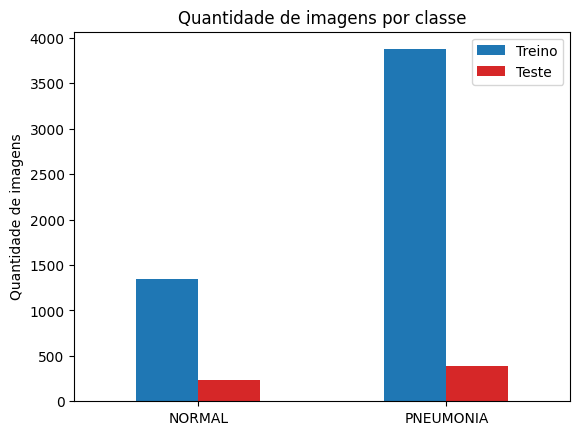

In [9]:
tabela_com_quantidade_de_imagens_por_classe = pd.DataFrame({
    'Treino': np.bincount(classes_do_treino_original),
    'Teste': np.bincount(classes_de_teste),
}, index=nomes_das_classes)

tabela_com_quantidade_de_imagens_por_classe.loc['% de pneumonia'] = (
    tabela_com_quantidade_de_imagens_por_classe.loc['PNEUMONIA'] / tabela_com_quantidade_de_imagens_por_classe.loc[nomes_das_classes].sum() * 100
).round(1)
print(tabela_com_quantidade_de_imagens_por_classe)

tabela_com_quantidade_de_imagens_por_classe.loc[nomes_das_classes].plot.bar(rot=0, color=['tab:blue', 'tab:red'])
plt.title('Quantidade de imagens por classe')
plt.ylabel('Quantidade de imagens')
plt.savefig('figura_1_distribuicao_das_classes.png', dpi=150, bbox_inches='tight')
plt.show()

O treino tem bem mais imagens de pneumonia do que normais (desbalanceamento), e a proporção no teste é diferente. Vamos usar pesos de classe.

Agora, as técnicas da Aula 1 aplicadas a uma radiografia de cada classe: imagem original, escala de cinza redimensionada, suavização gaussiana e bordas de Canny.

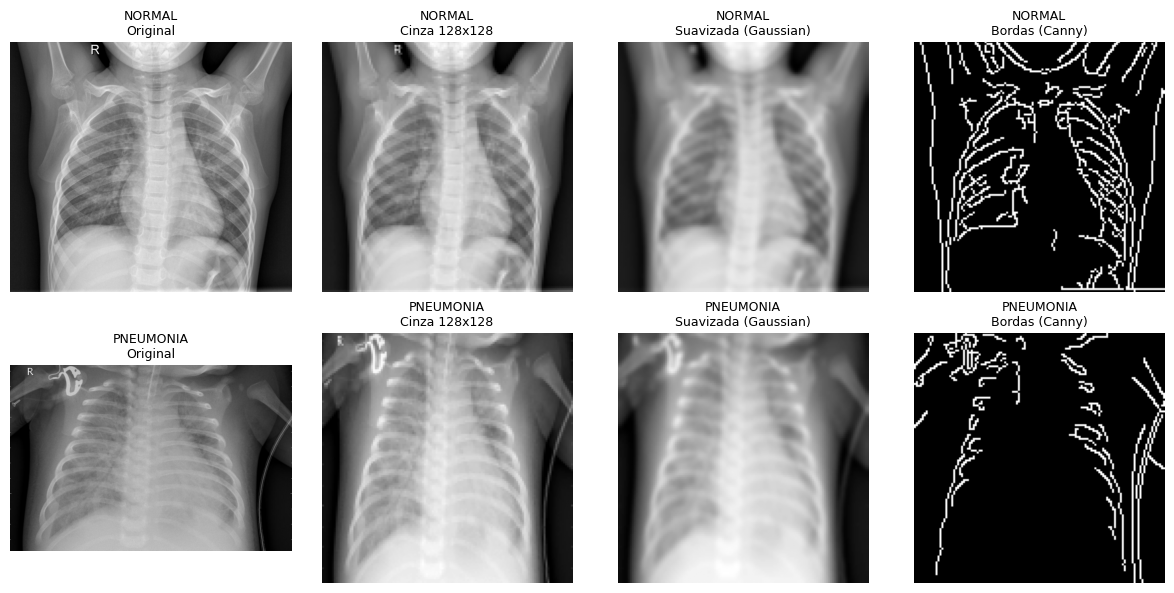

In [12]:
figura_das_etapas_do_opencv, eixos_das_etapas = plt.subplots(2, 4, figsize=(12, 6))
titulos_das_etapas = ['Original', 'Cinza 128x128', 'Suavizada (Gaussian)', 'Bordas (Canny)']

for linha, nome_da_classe in enumerate(nomes_das_classes):
    caminho_da_primeira_imagem_da_classe = sorted((pasta_com_treino_e_teste / 'train' / nome_da_classe).glob('*.jpeg'))[0]
    imagem_original_bgr = cv2.imread(str(caminho_da_primeira_imagem_da_classe))
    imagem_original_em_cinza = cv2.cvtColor(imagem_original_bgr, cv2.COLOR_BGR2GRAY)
    imagem_cinza_redimensionada = cv2.resize(imagem_original_em_cinza, (tamanho_da_imagem_em_pixels, tamanho_da_imagem_em_pixels), interpolation=cv2.INTER_AREA)
    imagem_suavizada = cv2.GaussianBlur(imagem_cinza_redimensionada, (5, 5), 0)
    imagem_com_bordas = cv2.Canny(imagem_cinza_redimensionada, 100, 200)

    for coluna, imagem_da_etapa in enumerate([imagem_original_em_cinza, imagem_cinza_redimensionada, imagem_suavizada, imagem_com_bordas]):
        eixos_das_etapas[linha, coluna].imshow(imagem_da_etapa, cmap='gray')
        eixos_das_etapas[linha, coluna].set_title(f'{nome_da_classe}\n{titulos_das_etapas[coluna]}', fontsize=9)
        eixos_das_etapas[linha, coluna].axis('off')

plt.tight_layout()
plt.savefig('figura_2_etapas_do_opencv.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Separando treino e validação

Separamos 20% do treino original para validação, mantendo a proporção de classes (`stratify`). O teste fica intocado até o final.

Também calculamos o **peso de cada classe**: a classe com menos imagens (normal) pesa mais na função de perda.

In [57]:
imagens_de_treino, imagens_de_validacao, classes_de_treino, classes_de_validacao = train_test_split(
    imagens_do_treino_original, classes_do_treino_original,
    test_size=0.2, stratify=classes_do_treino_original,
    random_state=semente_para_reproduzir_os_resultados)

tabela_da_divisao_dos_dados = pd.DataFrame({
    'Imagens': [len(classes_de_treino), len(classes_de_validacao), len(classes_de_teste)],
    '% de pneumonia': [round(classes.mean() * 100, 1) for classes in (classes_de_treino, classes_de_validacao, classes_de_teste)],
}, index=['Treino', 'Validação', 'Teste'])
print(tabela_da_divisao_dos_dados)

peso_de_cada_classe_no_treino = {
    numero_da_classe: len(classes_de_treino) / (2 * np.sum(classes_de_treino == numero_da_classe))
    for numero_da_classe in (0, 1)
}
print('Peso de cada classe:', peso_de_cada_classe_no_treino)

           Imagens  % de pneumonia
Treino        4172            74.3
Validação     1044            74.3
Teste          624            62.5
Peso de cada classe: {0: np.float64(1.9440820130475303), 1: np.float64(0.6731203614069055)}


## 5. Construindo e treinando a CNN (Aula 4)

Mesma estrutura da aula: três camadas `Conv2D` (32, 64 e 64 filtros 3x3, ReLU), dois `MaxPooling2D` 2x2, `Flatten`, `Dense` de 64 neurônios e saída `softmax`, aqui com **2 neurônios** (normal e pneumonia). Acrescentamos um `Dropout` de 0,5 antes da camada densa, para reduzir overfitting.

In [96]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(semente_para_reproduzir_os_resultados)
tf.config.experimental.enable_op_determinism()

modelo_cnn_para_detectar_pneumonia = models.Sequential()

modelo_cnn_para_detectar_pneumonia.add(layers.Conv2D(32, (3, 3), activation='relu',
                                                     input_shape=(tamanho_da_imagem_em_pixels, tamanho_da_imagem_em_pixels, 1)))
modelo_cnn_para_detectar_pneumonia.add(layers.MaxPooling2D((2, 2)))
modelo_cnn_para_detectar_pneumonia.add(layers.Conv2D(64, (3, 3), activation='relu'))
modelo_cnn_para_detectar_pneumonia.add(layers.MaxPooling2D((2, 2)))
modelo_cnn_para_detectar_pneumonia.add(layers.Conv2D(64, (3, 3), activation='relu'))
modelo_cnn_para_detectar_pneumonia.add(layers.Flatten())
modelo_cnn_para_detectar_pneumonia.add(layers.Dropout(0.5))
modelo_cnn_para_detectar_pneumonia.add(layers.Dense(64, activation='relu'))
modelo_cnn_para_detectar_pneumonia.add(layers.Dense(2, activation='softmax'))

modelo_cnn_para_detectar_pneumonia.compile(optimizer='adam',
                                           loss='sparse_categorical_crossentropy',
                                           metrics=['accuracy'])
modelo_cnn_para_detectar_pneumonia.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     3,211,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,267,202 (12.46 MB)

 Trainable params: 3,267,202 (12.46 MB)

 Non-trainable params: 0 (0.00 B)

In [97]:
parada_antecipada = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True)

historico_do_treinamento = modelo_cnn_para_detectar_pneumonia.fit(
    imagens_de_treino, classes_de_treino,
    epochs=numero_de_epocas,
    validation_data=(imagens_de_validacao, classes_de_validacao),
    class_weight=peso_de_cada_classe_no_treino,
    callbacks=[parada_antecipada],
    verbose=2)

Epoch 1/35
131/131 - 5s - 39ms/step - accuracy: 0.8447 - loss: 0.3091 - val_accuracy: 0.9511 - val_loss: 0.1279
Epoch 2/35
131/131 - 3s - 23ms/step - accuracy: 0.9362 - loss: 0.1663 - val_accuracy: 0.9397 - val_loss: 0.1478
Epoch 3/35
131/131 - 3s - 23ms/step - accuracy: 0.9576 - loss: 0.1175 - val_accuracy: 0.9358 - val_loss: 0.1601
Epoch 4/35
131/131 - 3s - 23ms/step - accuracy: 0.9662 - loss: 0.0868 - val_accuracy: 0.9569 - val_loss: 0.1074
Epoch 5/35
131/131 - 3s - 23ms/step - accuracy: 0.9708 - loss: 0.0759 - val_accuracy: 0.9473 - val_loss: 0.1302
Epoch 6/35
131/131 - 3s - 23ms/step - accuracy: 0.9708 - loss: 0.0741 - val_accuracy: 0.9617 - val_loss: 0.0915
Epoch 7/35
131/131 - 3s - 23ms/step - accuracy: 0.9720 - loss: 0.0800 - val_accuracy: 0.9617 - val_loss: 0.1039
Epoch 8/35
131/131 - 3s - 23ms/step - accuracy: 0.9753 - loss: 0.0631 - val_accuracy: 0.9713 - val_loss: 0.0784
Epoch 9/35
131/131 - 3s - 23ms/step - accuracy: 0.9791 - loss: 0.0507 - val_accuracy: 0.9626 - val_loss:

### Qual a melhor quantidade de épocas?

Olhamos as curvas de **validação**. A melhor época é a de **menor perda de validação**: antes dela o modelo ainda está aprendendo, e depois dela, se a perda de validação sobe enquanto a de treino continua caindo, o modelo começa a decorar o treino (overfitting). A linha tracejada marca essa época.

Melhor época (menor perda de validação): 12 de 35


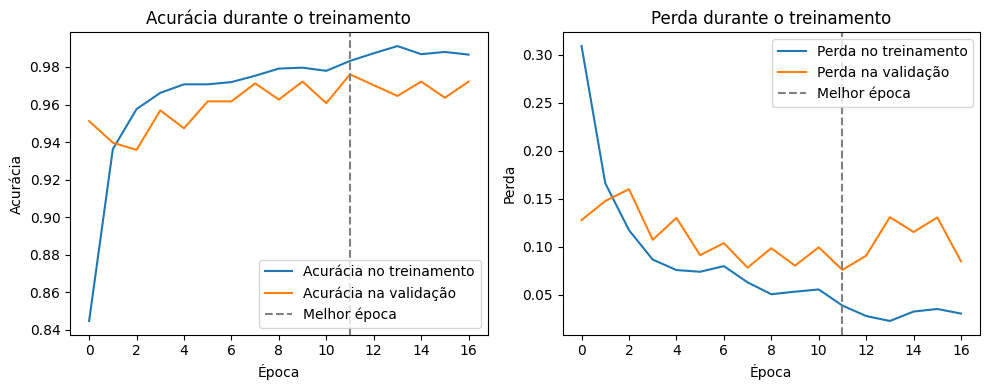

In [98]:
melhor_epoca_pela_perda_de_validacao = int(np.argmin(historico_do_treinamento.history['val_loss'])) + 1
print('Melhor época (menor perda de validação):',  melhor_epoca_pela_perda_de_validacao, 'de', numero_de_epocas)

figura_das_curvas, (eixo_da_acuracia, eixo_da_perda) = plt.subplots(1, 2, figsize=(10, 4))

eixo_da_acuracia.plot(historico_do_treinamento.history['accuracy'], label='Acurácia no treinamento')
eixo_da_acuracia.plot(historico_do_treinamento.history['val_accuracy'], label='Acurácia na validação')
eixo_da_acuracia.axvline(melhor_epoca_pela_perda_de_validacao - 1, color='gray', linestyle='--', label='Melhor época')
eixo_da_acuracia.set_title('Acurácia durante o treinamento'); eixo_da_acuracia.set_xlabel('Época'); eixo_da_acuracia.set_ylabel('Acurácia'); eixo_da_acuracia.legend()

eixo_da_perda.plot(historico_do_treinamento.history['loss'], label='Perda no treinamento')
eixo_da_perda.plot(historico_do_treinamento.history['val_loss'], label='Perda na validação')
eixo_da_perda.axvline(melhor_epoca_pela_perda_de_validacao - 1, color='gray', linestyle='--', label='Melhor época')
eixo_da_perda.set_title('Perda durante o treinamento'); eixo_da_perda.set_xlabel('Época'); eixo_da_perda.set_ylabel('Perda'); eixo_da_perda.legend()

plt.tight_layout()
plt.savefig('figura_3_curvas_de_treinamento.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Avaliando no conjunto de teste

No contexto médico, **deixar passar uma pneumonia (falso negativo) é pior do que um alarme falso**. Por isso olhamos principalmente o **recall da classe pneumonia**, junto com a precisão, o F1-score e a matriz de confusão.

Acurácia no teste: 0.747
              precision    recall  f1-score   support

      NORMAL      0.963     0.338     0.500       234
   PNEUMONIA      0.714     0.992     0.830       390

    accuracy                          0.747       624
   macro avg      0.839     0.665     0.665       624
weighted avg      0.808     0.747     0.707       624

AUC-ROC: 0.907
Falsos negativos (pneumonia não detectada): 3
Falsos positivos (normal classificado como pneumonia): 155


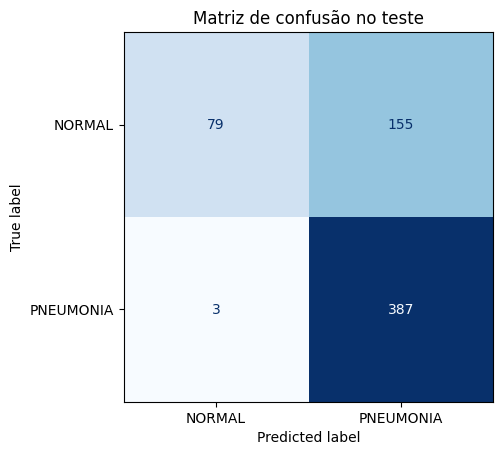

In [99]:
perda_no_teste, acuracia_no_teste = modelo_cnn_para_detectar_pneumonia.evaluate(imagens_de_teste, classes_de_teste, verbose=0)
print(f'Acurácia no teste: {acuracia_no_teste:.3f}')

probabilidades_de_cada_classe_no_teste = modelo_cnn_para_detectar_pneumonia.predict(imagens_de_teste, verbose=0)
classes_previstas_no_teste = np.argmax(probabilidades_de_cada_classe_no_teste, axis=1)
probabilidade_de_pneumonia_no_teste = probabilidades_de_cada_classe_no_teste[:, 1]

print(classification_report(classes_de_teste, classes_previstas_no_teste, target_names=nomes_das_classes, digits=3, zero_division=0))
print('AUC-ROC:', round(roc_auc_score(classes_de_teste, probabilidade_de_pneumonia_no_teste), 3))

matriz_de_confusao_no_teste = confusion_matrix(classes_de_teste, classes_previstas_no_teste)
verdadeiros_negativos, falsos_positivos, falsos_negativos, verdadeiros_positivos = matriz_de_confusao_no_teste.ravel()
print('Falsos negativos (pneumonia não detectada):', falsos_negativos)
print('Falsos positivos (normal classificado como pneumonia):', falsos_positivos)

ConfusionMatrixDisplay(matriz_de_confusao_no_teste, display_labels=nomes_das_classes).plot(cmap='Blues', colorbar=False)
plt.title('Matriz de confusão no teste')
plt.savefig('figura_5_matriz_de_confusao_no_teste.png', dpi=150, bbox_inches='tight')
plt.show()

Como na Aula 4, vemos algumas imagens de teste com a previsão do modelo: **azul** quando acertou e **vermelho** quando errou. Sorteamos 25 imagens, porque o teste está ordenado por classe.

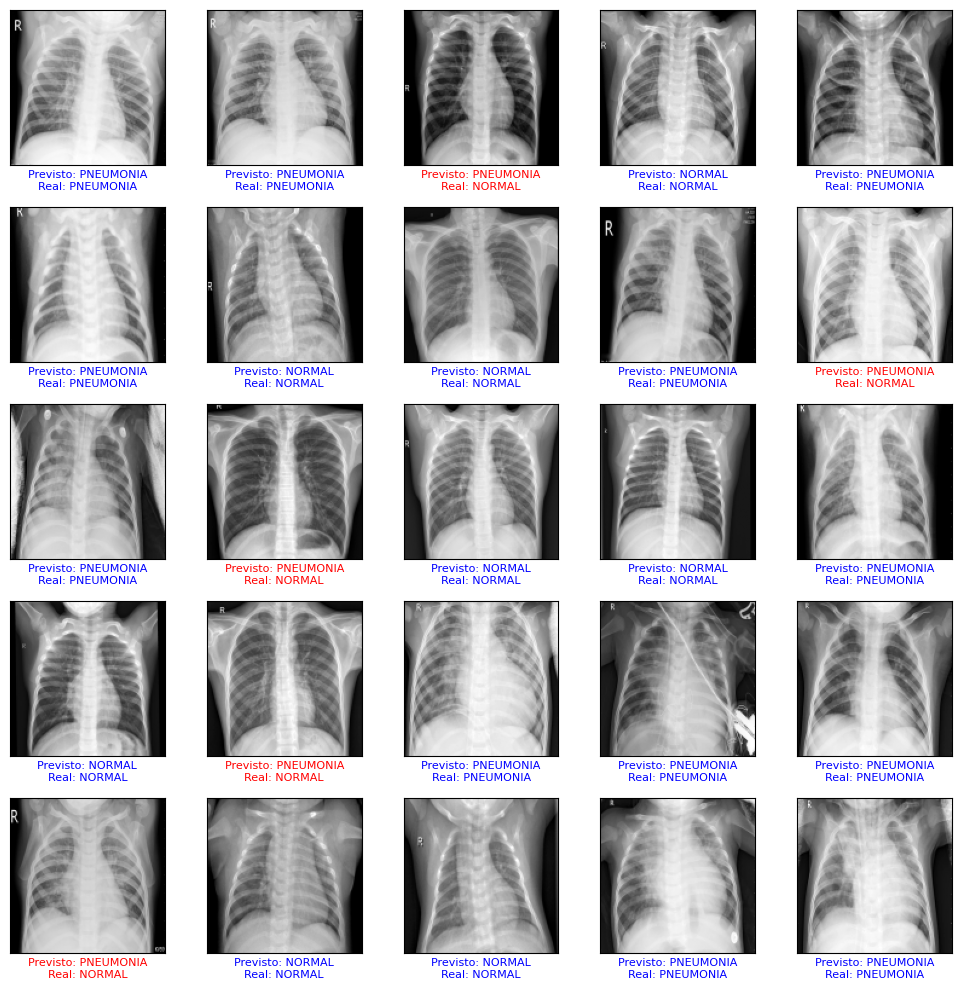

In [ ]:
posicoes_sorteadas_do_teste = np.random.choice(len(classes_de_teste), 25, replace=False)

plt.figure(figsize=(10, 10))
for posicao_no_grafico, posicao_da_imagem in enumerate(posicoes_sorteadas_do_teste):
    plt.subplot(5, 5, posicao_no_grafico + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(imagens_de_teste[posicao_da_imagem].reshape(tamanho_da_imagem_em_pixels, tamanho_da_imagem_em_pixels), cmap='gray')

    classe_prevista = classes_previstas_no_teste[posicao_da_imagem]
    classe_verdadeira = classes_de_teste[posicao_da_imagem]
    cor_do_texto = 'blue' if classe_prevista == classe_verdadeira else 'red'
    plt.xlabel(f'Previsto: {nomes_das_classes[classe_prevista]}\nReal: {nomes_das_classes[classe_verdadeira]}', color=cor_do_texto, fontsize=8)

plt.tight_layout()
plt.savefig('figura_4_previsoes_no_teste.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Salvando os resultados para o relatório

In [ ]:
resultados_do_teste = classification_report(classes_de_teste, classes_previstas_no_teste,
                                            target_names=nomes_das_classes, output_dict=True, zero_division=0)
resultados_do_teste['acuracia_do_evaluate'] = float(acuracia_no_teste)
resultados_do_teste['auc_roc'] = float(roc_auc_score(classes_de_teste, probabilidade_de_pneumonia_no_teste))
resultados_do_teste['matriz_de_confusao'] = {'verdadeiros_negativos': int(verdadeiros_negativos), 'falsos_positivos': int(falsos_positivos),
                                             'falsos_negativos': int(falsos_negativos), 'verdadeiros_positivos': int(verdadeiros_positivos)}
resultados_do_teste['quantidade_de_imagens_por_classe'] = tabela_com_quantidade_de_imagens_por_classe.to_dict()
resultados_do_teste['divisao_dos_dados'] = tabela_da_divisao_dos_dados.to_dict()
resultados_do_teste['pesos_de_classe'] = {str(k): float(v) for k, v in peso_de_cada_classe_no_treino.items()}
resultados_do_teste['numero_de_epocas'] = numero_de_epocas
resultados_do_teste['melhor_epoca_pela_perda_de_validacao'] = melhor_epoca_pela_perda_de_validacao
resultados_do_teste['total_de_parametros'] = int(modelo_cnn_para_detectar_pneumonia.count_params())
resultados_do_teste['historico'] = {nome: [float(v) for v in valores] for nome, valores in historico_do_treinamento.history.items()}

with open('resultados_do_teste.json', 'w') as arquivo_de_resultados:
    json.dump(resultados_do_teste, arquivo_de_resultados, indent=2)

with zipfile.ZipFile('resultados_visao_computacional.zip', 'w') as arquivo_zip:
    for nome_do_arquivo in sorted(os.listdir('.')):
        if nome_do_arquivo.startswith('figura_') or nome_do_arquivo == 'resultados_do_teste.json':
            arquivo_zip.write(nome_do_arquivo)
print(zipfile.ZipFile('resultados_visao_computacional.zip').namelist())

['figura_1_distribuicao_das_classes.png', 'figura_2_etapas_do_opencv.png', 'figura_3_curvas_de_treinamento.png', 'figura_4_previsoes_no_teste.png', 'figura_5_matriz_de_confusao_no_teste.png', 'resultados_do_teste.json']


In [ ]:
try:
    from google.colab import files
    files.download('resultados_visao_computacional.zip')
except ImportError:
    print('Fora do Colab: o zip ficou na pasta atual.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Limitações

- Imagens de crianças de um único hospital: não há garantia de que o modelo funcione em outras populações ou equipamentos.
- O mesmo paciente pode ter várias radiografias; como a validação foi sorteada entre imagens, ela pode ficar otimista.
- A proporção de pneumonia no teste é diferente da do treino, e o teste é pequeno (624 imagens): os números têm incerteza.
- O modelo é apoio à triagem. **O médico tem sempre a palavra final.**